# Plug and play photovoltaic panels
Recently, Synergrid has published a technical directive listing the requirements for plug and play devices that can store or generate electrical energy. They also provide a list indicating which equipment is homologated to be used in Belgium. These plug-and-play devices can be purchased by privates and installed without contacting a technician directly by connecting them to normal electrical outlets. 

The question is then, does it make sense to buy them?

This depends of course on the amount of energy that can be harvested from the sun, and the electric energy that is consumed by the dwelling. 


# Calculating the solar radiation
The amount of solar energy that hits a solar panel installed on a balcony depends on a variety of factors:
* The orientation of the solar panel (azimuth). Ideally, this should be towards the South (180 degrees), but anything from East (90 degrees) to West (270) can be considered. Outside of this range, there is not enough sunlight to justify the installation of a solar panel.
* The slope of the solar panel, i.e. the tilt from the surface parallel to the ground. For a panel that is attached to the exterior facade of the balcony, the slope is usually fixed at 90 degrees which is not ideal especially for the summer months where the sun is high in the sky.
* Surrounding buildings. In a city such as Brussels, buildings can block the Sun for long hours each days, substantially reducing the amount of direct light hitting the solar panel.
* The cloud cover, which is of course quite a big problem in Brussels.

Historic irradiance data (i.e. the amount of solar energy hitting a specific surface in the last years) based on the azimuth and the slope can be easily retrieved using a tool such as PVGIS: you need to provide the address of your home, then you have to fill the information related to the orientation, slope and horizon (i.e., the occlusion caused by the surrounding buildings). The balcony in my apartment is located in direction SW (azimuth = 225 degrees) and the slope of a potential PV panel attached to the balcony would be 90 degrees. 

Unfortunately, the information regarding the horizon is much harder to get. The way I managed to do it is by exploiting the UrbIS Buildings dataset. This dataset contains the 3D data for all the buildings in the Brussels Region. The data can be downloaded and analyzed using the geopandas Python library. Doing this, I managed to reconstruct the horizon elevation that I see from my balcony for each azimuthal degree, which looks something like this:


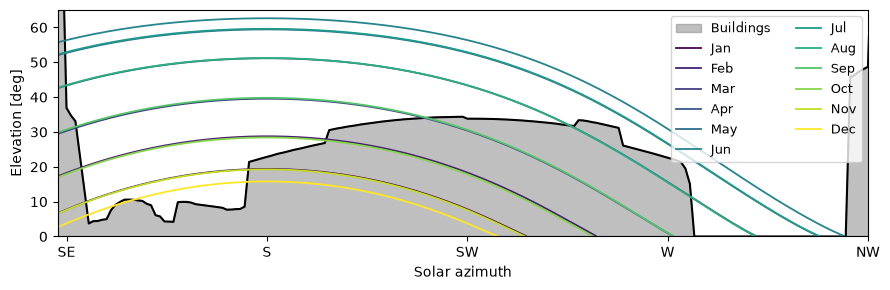

In [1]:
import pvlib
import pandas as pd
import matplotlib.pyplot as plt

hz = pd.read_csv("../data/horizon.csv")

# Location in Brussels
latitude = 50.817205
longitude = 4.377434
azimuth = 223  # SW

# Belgian time zone
tz = "Europe/Brussels"
year = 2026

dates = pd.to_datetime([
    f"{year}-01-21",
    f"{year}-02-21",
    f"{year}-03-21",
    f"{year}-04-21",
    f"{year}-05-21",
    f"{year}-06-21",
    f"{year}-07-21",
    f"{year}-08-21",
    f"{year}-09-21",
    f"{year}-10-21",
    f"{year}-11-21",
    f"{year}-12-21",
])

solar_paths = {}

for date in dates:
    times = pd.date_range(start=date, end=date + pd.Timedelta(days=1), freq="2min", tz=tz)
    solar_position = pvlib.solarposition.get_solarposition(times, latitude, longitude)

    # Keep Sun above astronomical horizon
    solar_position = solar_position[solar_position["apparent_elevation"] > 0]
    solar_paths[date.strftime("%b")] = solar_position


fig, ax = plt.subplots(figsize=(9, 3))
az_horizon = hz["azimuth"].values
el_horizon = hz["horizon_height"].values

ax.fill_between(az_horizon, 0, el_horizon, color="gray", alpha=0.5, label="Buildings")
ax.plot(az_horizon, el_horizon, color="black", linewidth=1.5)

cmap = plt.cm.viridis
for i, (month, sun) in enumerate(solar_paths.items()):
    mask = ((sun["azimuth"] >= 0) &(sun["azimuth"] <= 360))
    ax.plot(sun.loc[mask, "azimuth"], sun.loc[mask, "apparent_elevation"], color=cmap(i / 11), linewidth=1.3, label=month)

ax.set_xlim(azimuth-90, azimuth+90)
ax.set_ylim(0, 65)

ax.set_xticks([135, 180, 225, 270, 315], ["SE", "S", "SW", "W", "NW"])
ax.set_xlabel("Solar azimuth")
ax.set_ylabel("Elevation [deg]")
ax.legend(ncol=2, loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()


As you can see, I have quite a big building in front of my balcony. During the summer months, the sun is higher than the building for most of the day. However, this means also that it will hit the solar panel with a large angle, which is not ideal. During the winter months, the solar panel will get a bit of sunlight only during late morning. 

Through pvlib, I have also retrieved the solar irradiance data for the last 5 years available, from 2018 to 2023. This data has hourly information on the irradiance, divided into the direct energy (the solar rays that hit the panel directly and that can be blocked by the buildings) and diffuse energy, which is the light scattered by the sky and coming from all directions. 

For example, on the 11th of October 2023, the Sun would have hit directly my solar panel only between 11:00 and 15:00, while the diffuse radiation would have contributed from 9:00 to 18:00 


In [2]:
# PVGIS data for 5 years
import numpy as np
import pandas as pd
import pvlib
from pvlib.iotools import get_pvgis_hourly
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

lat, lon, alt = 50.817205, 4.377434, 90.452
tilt, azimuth = 90, 223          # vertical, south-facing (pvlib: 180 = south)
tz = "Europe/Brussels"

data, meta = get_pvgis_hourly(
    latitude=lat,
    longitude=lon,
    start=2019,
    end=2023,
    raddatabase="PVGIS-SARAH3",
    components=True,
    surface_tilt=tilt,
    surface_azimuth=azimuth,
    usehorizon=False
)

data.index = data.index.tz_convert("Europe/Brussels")
site = pvlib.location.Location(latitude=lat, longitude=lon, tz=tz, altitude=alt)
solpos = site.get_solarposition(data.index)

hz = pd.read_csv("../data/horizon.csv")
hz_az, hz_hg = hz["azimuth"].values, hz["horizon_height"].values
sun_horizon = np.interp(solpos["azimuth"], hz_az, hz_hg, period=360)
blocked = (solpos["apparent_elevation"] <= sun_horizon)
data["poa_direct_corr"] = data["poa_direct"].where(~blocked, 0.0)

h = np.radians(hz_hg)
diff = ((hz_az - azimuth + 180) % 360) - 180
front = np.abs(diff) <= 90
weights = np.cos(np.radians(diff[front]))

svf = np.sum(weights * np.cos(h[front])**2) / np.sum(weights)

data['poa_diffuse'] = svf*data['poa_sky_diffuse'] + data['poa_ground_diffuse']
data['poa_global'] = data['poa_direct_corr'] + data['poa_diffuse']


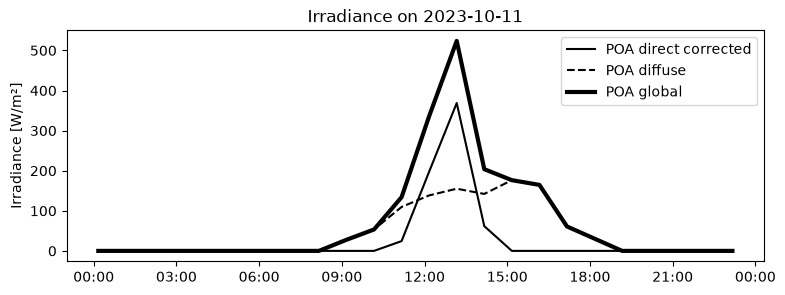

In [3]:
day = "2023-10-11"
day_end = "2023-10-11 23:59"

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(data["poa_direct_corr"].loc[day], label="POA direct corrected", c='k')
ax.plot(data["poa_diffuse"].loc[day], label="POA diffuse", c='k', ls='--')
ax.plot(data["poa_global"].loc[day], label="POA global", c ='k', lw=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=tz))
ax.set_ylabel("Irradiance [W/m²]")
ax.set_title(f"Irradiance on {day}")
ax.legend()
ax.grid(False)

plt.show()

From this dataset, we can compute how much energy the solar panel would gather each year. To perform the calculation I’m employing the following setup:
* Number of solar panels: 2
* Length of the solar panel: 1.96 m
* Height of the solar panel: 1.134 m
* Total area: 4.45 m2
* Efficiency of the solar panel: 25.3%
* Total efficiency of the system: 85%
* Nominal power: 1000 W
* Inverter: 800 W (not clear if this is the maximum allowed for plug & play installations)
* Price: 550 Eur

The yearly amount of energy that would have been produced by the PV system fluctuates around 500/600 kWh. 

In [6]:
# Power output
from pvlib.temperature import sapm_cell
temp_cell = sapm_cell(
    poa_global=data["poa_global"],
    temp_air=data["temp_air"],
    wind_speed=data["wind_speed"],
    a=-3.56,
    b=-0.075,
    deltaT=3
)

n_panels = 2
length = 1.96  #m
height = 1.134  #m
area = n_panels * length * height #m2
eta_panel = 0.253
eta_sys = 0.85
P_nom = n_panels * 500 #W
price = 550  #Eur

gamma = -0.0035  # 1/°C
power = (data["poa_global"]* P_nom/1000 * (1 + gamma*(temp_cell - 25)))

data['P_prod'] = power * eta_sys  #W
data['E_prod'] = data['P_prod']/1000  # kWh

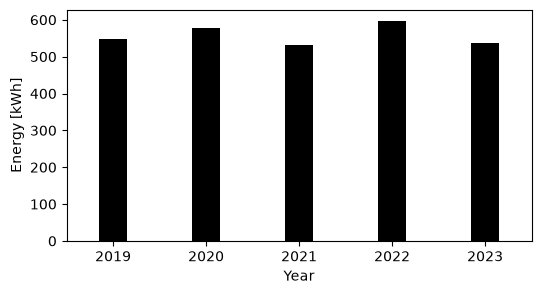

In [7]:
# Plot yearly production
yearly = data['E_prod'].resample("YE").sum()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(yearly.index.year, yearly.values, width=0.3, color='black')
ax.set_xlabel("Year")
ax.set_xlim(2018.5, 2023.5)
ax.set_ylabel("Energy [kWh]")
plt.show()

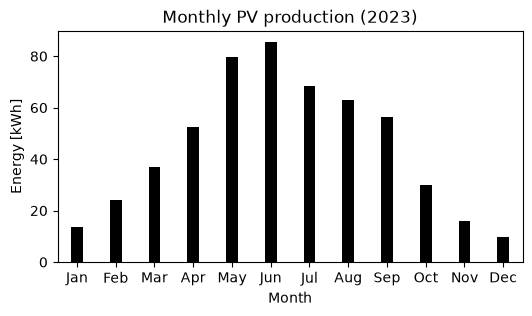

In [8]:
# Plot monthly production
monthly_2023 = (data.loc["2023", "E_prod"].resample("ME").sum())
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(monthly_2023.index.month, monthly_2023.values, width=0.3, color='black')
ax.set_xlabel("Month")
ax.set_xlim(0.5, 12.5)
ax.set_ylabel("Energy [kWh]")
ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Monthly PV production (2023)")
plt.show()

Given my orientation, the best months would be from April to September, with a sharp drop from October to March.